# **Recursive Neural Network**
This is the main task of our project. This document will be divided in three sections:
1. Vanilla RNN: like Minecraft, no mods;
2. GRU: minions, tonight, we steal the moon;
3. LSTM: improved version of the RNN, designed to capture long-term dependencies in sequential data.
4. Attention: pefoza.


## IMPORTS AND SETUP

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    GITHUB_USER = "SinghSahiljit44"  # Es. sahiljit
    REPO_NAME = "Weather_forecasting"
    REPO_URL = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"

    # Clona la repository se non è già stata clonata nella sessione
    if not os.path.exists(REPO_NAME):
        !git clone {REPO_URL}

    # Cambia la directory di lavoro nella root del progetto
    os.chdir(REPO_NAME)

    # Installa le dipendenze necessarie nell'ambiente di Colab
    %pip install -q -r requirements.txt

    PROJECT_ROOT = Path.cwd()
else:
    # --- CONFIGURAZIONE LOCALE  ---
    PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
    os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print(f" [OK] Ambiente rilevato: {'Google Colab' if IN_COLAB else 'Locale'}")
print(f" [OK] Directory di lavoro impostata a: {Path.cwd()}")

 [OK] Ambiente rilevato: Locale
 [OK] Directory di lavoro impostata a: /home/matteo/Documents/GitHub/Weather_forecasting


In [2]:
import copy
from itertools import product

import numpy as np
import pandas as pd
import optuna
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

import src.utils.metrics as metrics
from src.data.preprocessing import get_split

RANDOM_STATE = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

/home/matteo/Documents/GitHub/Weather_forecasting/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


## DATASET

In [3]:
split = get_split()
features = split.get_features()

split.define_target("t2m_mean")
(X_train, yt_train), (X_val, yt_val), (X_test, yt_test) = split.get(features)
split.define_target("tp_mm")
(_, yp_train), (_, yp_val), (_, yp_test) = split.get(features)

y_train = pd.concat({"t2m_mean": yt_train, "tp_mm": yp_train}, axis=1)
y_val   = pd.concat({"t2m_mean": yt_val,   "tp_mm": yp_val},   axis=1)
y_test  = pd.concat({"t2m_mean": yt_test,  "tp_mm": yp_test},  axis=1)

target_scales = y_train.std(axis=0, ddof=0).replace(0, 1)

x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)

X_full = pd.DataFrame(
    x_scaler.transform(split.df[features]),
    index=split.df.index,
    columns=features
)

N_FEATURES = len(features)
N_OUTPUTS = y_train.shape[1]

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape} | y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")

X_train: (10168, 26) | y_train: (10168, 60)
X_val:   (1431, 26) | y_val:   (1431, 60)
X_test:  (1430, 26) | y_test:  (1430, 60)


## UTILITES 

In [4]:
def make_sequences(X_full, y, seq_len):
    values = X_full.to_numpy(dtype=np.float32)
    windows = np.lib.stride_tricks.sliding_window_view(values, seq_len, axis=0).transpose(0, 2, 1)

    start = X_full.index.get_indexer(y.index) - seq_len + 1
    ok = start >= 0
    X_seq = windows[start[ok]]

    finite = np.isfinite(X_seq).all(axis=(1, 2))  # scarta finestre con NaN (lag/rolling iniziali)
    return X_seq[finite], y.loc[ok].loc[finite]


def prepare_data(seq_len):
    data = {}
    for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
        X_seq, y_seq = make_sequences(X_full, y, seq_len)
        data[name] = (X_seq, y_seq, y_scaler.transform(y_seq).astype(np.float32))
    return data


def make_loader(X, y, batch_size, shuffle):
    dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

In [5]:
class RecurrentRegressor(nn.Module):
    CELLS = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}

    def __init__(self, n_features, n_outputs, hidden_size=64, num_layers=1,
                 dropout=0.0, cell="rnn"):
        super().__init__()
        self.rnn = self.CELLS[cell](
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, n_outputs)
        )


    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])

In [6]:
def set_seed(seed=RANDOM_STATE):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def evaluate_loss(model, loader):
    model.eval()
    mae = mse = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        err = model(xb) - yb
        mae += err.abs().mean().item() * len(xb)
        mse += err.pow(2).mean().item() * len(xb)
    n = len(loader.dataset)
    return mae / n, mse / n


def train_model(model, data, lr=1e-3, weight_decay=0.0, batch_size=64,
                epochs=200, patience=20, trial=None):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.HuberLoss()

    X_tr, _, y_tr = data["train"]
    X_va, _, y_va = data["val"]
    train_loader = make_loader(X_tr, y_tr, batch_size, shuffle=True)
    val_loader = make_loader(X_va, y_va, 1024, shuffle=False)

    history = {"loss": [], "val_loss": [], "mse": [], "val_mse": []}
    best_loss, best_state, wait = np.inf, None, 0

    for epoch in range(epochs):
        model.train()
        run_mae = run_mse = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # importante per vanilla RNN
            optimizer.step()
            run_mae += (pred - yb).abs().mean().item() * len(xb)
            run_mse += (pred - yb).pow(2).mean().item() * len(xb)

        n = len(train_loader.dataset)
        val_mae, val_mse = evaluate_loss(model, val_loader)
        history["loss"].append(run_mae / n)
        history["mse"].append(run_mse / n)
        history["val_loss"].append(val_mae)
        history["val_mse"].append(val_mse)

        if trial is not None:
            trial.report(val_mae, step=epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if val_mae < best_loss:
            best_loss, best_state, wait = val_mae, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return model, history


@torch.no_grad()
def predict(model, X_seq, y_like):
    model.eval()
    loader = DataLoader(TensorDataset(torch.from_numpy(X_seq)), batch_size=1024)
    pred = torch.cat([model(xb.to(DEVICE)).cpu() for (xb,) in loader]).numpy()
    pred = pd.DataFrame(y_scaler.inverse_transform(pred), index=y_like.index, columns=y_like.columns)
    pred["tp_mm"] = pred["tp_mm"].clip(lower=0)  # pioggia >= 0
    return pred


def normalized_mae(y_true, y_pred):
    scales = target_scales.reindex(y_true.columns)
    return (y_true - y_pred).abs().div(scales, axis=1).to_numpy().mean()

In [7]:
def run_config(cell="rnn", seq_len=30, hidden_size=64, num_layers=1, dropout=0.0,
               lr=1e-3, weight_decay=0.0, batch_size=64, epochs=200, patience=20,
               trial=None):
    set_seed()
    data = prepare_data(seq_len)
    model = RecurrentRegressor(N_FEATURES, N_OUTPUTS, hidden_size, num_layers, dropout, cell)
    model, history = train_model(model, data, lr, weight_decay, batch_size, epochs, patience, trial)
    preds = {name: predict(model, X, y) for name, (X, y, _) in data.items()}
    return model, history, data, preds


def show_results(model_name, data, preds, splits=("train", "val")):
    plot_split = splits[-1]
    for target, unit, tol in [("t2m_mean", "°C", 2), ("tp_mm", "mm", None)]:
        metrics.plot_rmse(
            data[plot_split][1][target],
            preds[plot_split][target],
            f"{model_name}, {target}: {plot_split} RMSE by lead time",
            unit
        )
        table = metrics.metrics_table(
            {s.capitalize(): (data[s][1][target], preds[s][target]) for s in splits},
            tolerance=tol
        )
        display(table.style.format("{:.3f}"))

In [8]:
def evaluate_config(cell, seq_len, hidden_size, num_layers):
    _, history, data, preds = run_config(
        cell=cell, seq_len=seq_len, hidden_size=hidden_size, num_layers=num_layers
    )
    y_true, y_pred = data["val"][1], preds["val"]
    return {
        "seq_len": seq_len,
        "hidden_size": hidden_size,
        "num_layers": num_layers,
        "epochs": len(history["loss"]),
        "Val normalized MAE": normalized_mae(y_true, y_pred),
        "Val temp MAE": metrics.get_mean_absolute_error(y_true["t2m_mean"], y_pred["t2m_mean"]),
        "Val precip MAE": metrics.get_mean_absolute_error(y_true["tp_mm"], y_pred["tp_mm"]),
    }


def manual_search(cell, seq_lens=(14, 30, 60), hidden_sizes=(32, 64, 128), layers=(1, 2)):
    results = [
        evaluate_config(cell, s, h, l)
        for s, h, l in product(seq_lens, hidden_sizes, layers)
    ]
    return (
        pd.DataFrame(results)
        .sort_values("Val normalized MAE")
        .reset_index(drop=True)
    )


def make_objective(cell, seq_lens=(7, 14, 30, 60)):
    def objective(trial):
        params = {
            "seq_len":      trial.suggest_categorical("seq_len", list(seq_lens)),
            "hidden_size":  trial.suggest_int("hidden_size", 16, 256, log=True),
            "num_layers":   trial.suggest_int("num_layers", 1, 3),
            "dropout":      trial.suggest_float("dropout", 0.0, 0.5),
            "lr":           trial.suggest_float("lr", 1e-4, 1e-2, log=True),
            "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
            "batch_size":   trial.suggest_categorical("batch_size", [32, 64, 128, 256]),
        }
        _, _, data, preds = run_config(cell=cell, trial=trial, **params)
        return normalized_mae(data["val"][1], preds["val"])
    return objective


def run_study(cell, n_trials=50, **objective_kwargs):
    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=10)
    )
    study.optimize(make_objective(cell, **objective_kwargs), n_trials=n_trials, show_progress_bar=True)

    print("Best validation normalized MAE:", study.best_value)
    print("Best hyperparameters:", study.best_params)
    display(study.trials_dataframe().sort_values("value")[["number", "value", "state"]].head(10))
    return study


models = {}
test_predictions = {}

## **VANILLA RNN**

### DEFAULT PERFORMANCE

Epochs: 23


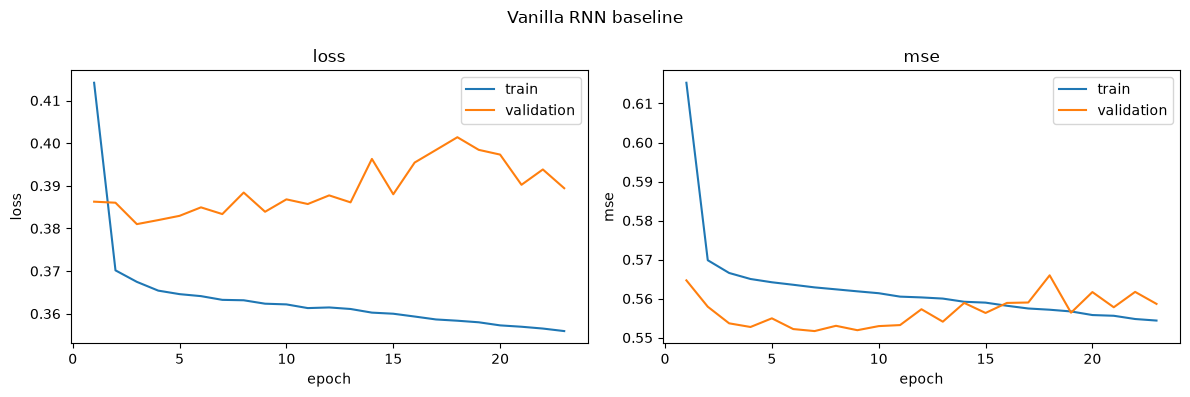

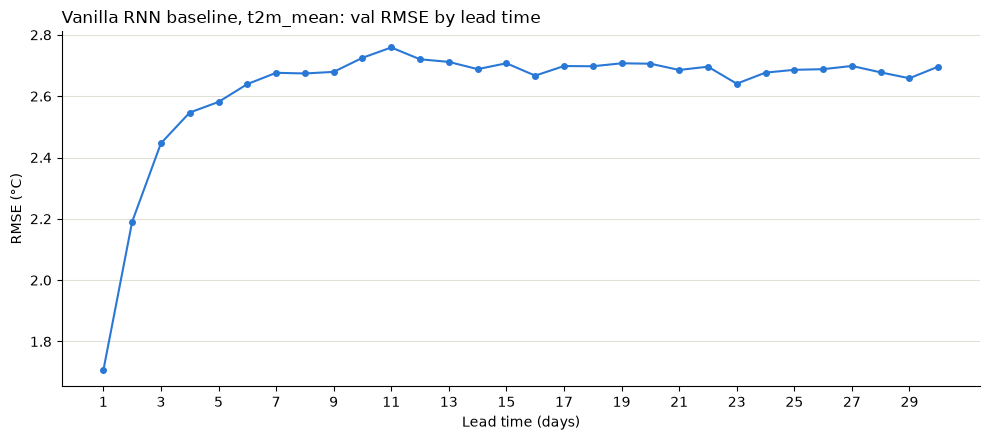

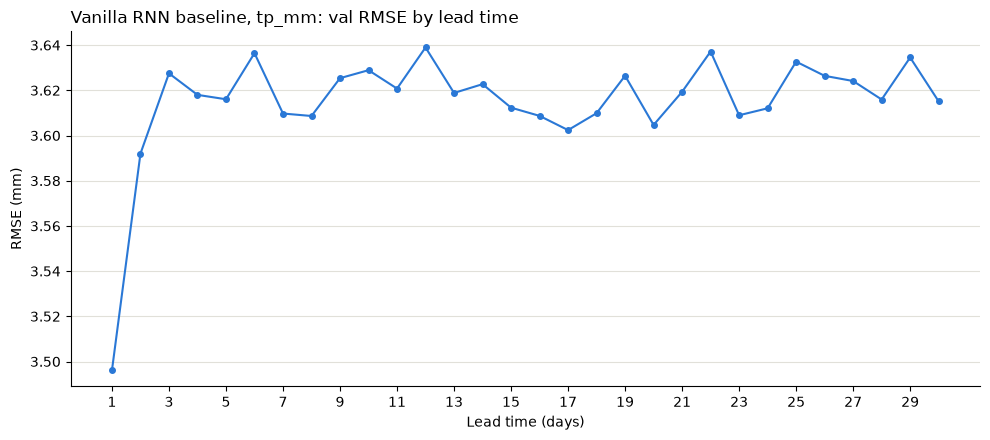

In [9]:
rnn, history, data, preds = run_config(cell="rnn")

print(f"Epochs: {len(history['loss'])}")
metrics.plot_training_history(history, metric="mse", title="Vanilla RNN baseline")
show_results("Vanilla RNN baseline", data, preds)

### MANUAL HYPERPARAMETER SEARCH

In [10]:
results_rnn = manual_search("rnn")
display(results_rnn.round(4))

,seq_len,hidden_size,num_layers,epochs,Val normalized MAE,Val temp MAE,Val precip MAE
0,14,32,2,23,0.3779,2.1067,1.7483
1,60,32,2,26,0.3780,2.0651,1.7686
2,14,64,2,26,0.3785,2.0949,1.7583
3,14,128,2,25,0.3789,2.0743,1.7710
4,30,32,2,24,0.3791,2.0763,1.7713
5,60,64,2,26,0.3797,2.0771,1.7751
6,14,128,1,22,0.3797,2.0489,1.7887
7,30,128,1,26,0.3802,2.0569,1.7886
8,60,128,2,25,0.3803,2.0823,1.7775
9,60,128,1,22,0.3805,2.0719,1.7838


### OPTUNA

In [11]:
study_rnn = run_study("rnn", n_trials=50)

[I 2026-11-28 11:51:13,699] A new study created in memory with name: no-name-a0a1f2aa-4818-4597-b1b5-feb4cc6945c6
Best trial: 0. Best value: 0.378611:   2%|▏         | 1/50 [00:03<03:12,  3.93s/it]

[I 2026-11-28 11:51:17,633] Trial 0 finished with value: 0.37861081561873466 and parameters: {'seq_len': 14, 'hidden_size': 24, 'num_layers': 1, 'dropout': 0.02904180608409973, 'lr': 0.005399484409787433, 'weight_decay': 6.358358856676247e-05, 'batch_size': 128}. Best is trial 0 with value: 0.37861081561873466.


Best trial: 0. Best value: 0.378611:   4%|▍         | 2/50 [00:08<03:23,  4.24s/it]

[I 2026-11-28 11:51:22,094] Trial 1 finished with value: 0.379247694945033 and parameters: {'seq_len': 60, 'hidden_size': 68, 'num_layers': 2, 'dropout': 0.14561457009902096, 'lr': 0.0016738085788752138, 'weight_decay': 2.62108787826544e-06, 'batch_size': 256}. Best is trial 0 with value: 0.37861081561873466.


Best trial: 2. Best value: 0.377246:   6%|▌         | 3/50 [00:40<13:14, 16.90s/it]

[I 2026-11-28 11:51:54,050] Trial 2 finished with value: 0.3772461199297427 and parameters: {'seq_len': 30, 'hidden_size': 85, 'num_layers': 1, 'dropout': 0.03252579649263976, 'lr': 0.007902619549708232, 'weight_decay': 0.0007886714129990489, 'batch_size': 32}. Best is trial 2 with value: 0.3772461199297427.


... (91 outputs left out)

[I 2026-11-28 11:58:47,436] Trial 48 pruned. 


Best trial: 49. Best value: 0.371196: 100%|██████████| 50/50 [07:52<00:00,  9.46s/it]

[I 2026-11-28 11:59:06,519] Trial 49 finished with value: 0.37119628029357205 and parameters: {'seq_len': 7, 'hidden_size': 29, 'num_layers': 3, 'dropout': 0.32210457549685034, 'lr': 0.0008940012158177949, 'weight_decay': 3.65584262943515e-05, 'batch_size': 64}. Best is trial 49 with value: 0.37119628029357205.
Best validation normalized MAE: 0.37119628029357205
Best hyperparameters: {'seq_len': 7, 'hidden_size': 29, 'num_layers': 3, 'dropout': 0.32210457549685034, 'lr': 0.0008940012158177949, 'weight_decay': 3.65584262943515e-05, 'batch_size': 64}


,number,value,state
49,49,0.371196,COMPLETE
34,34,0.371485,COMPLETE
32,32,0.371683,COMPLETE
47,47,0.371890,COMPLETE
25,25,0.371896,COMPLETE
11,11,0.372013,COMPLETE
35,35,0.372020,COMPLETE
28,28,0.372270,COMPLETE
27,27,0.372301,COMPLETE
45,45,0.372673,COMPLETE


### TESTING

Best hyperparameters: {'seq_len': 7, 'hidden_size': 29, 'num_layers': 3, 'dropout': 0.32210457549685034, 'lr': 0.0008940012158177949, 'weight_decay': 3.65584262943515e-05, 'batch_size': 64}


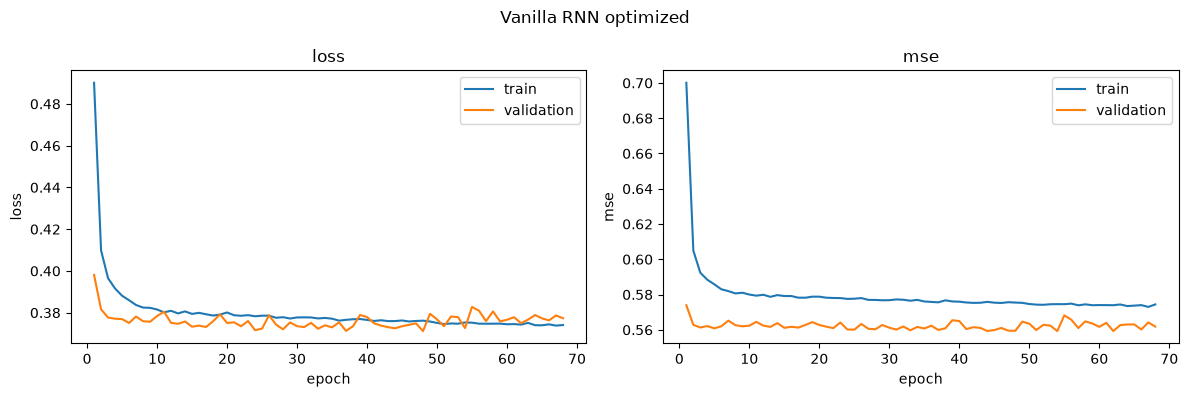

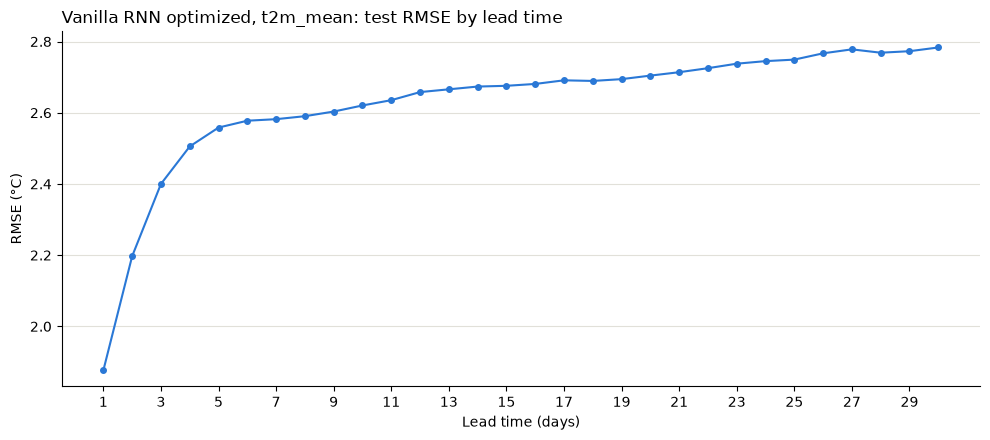

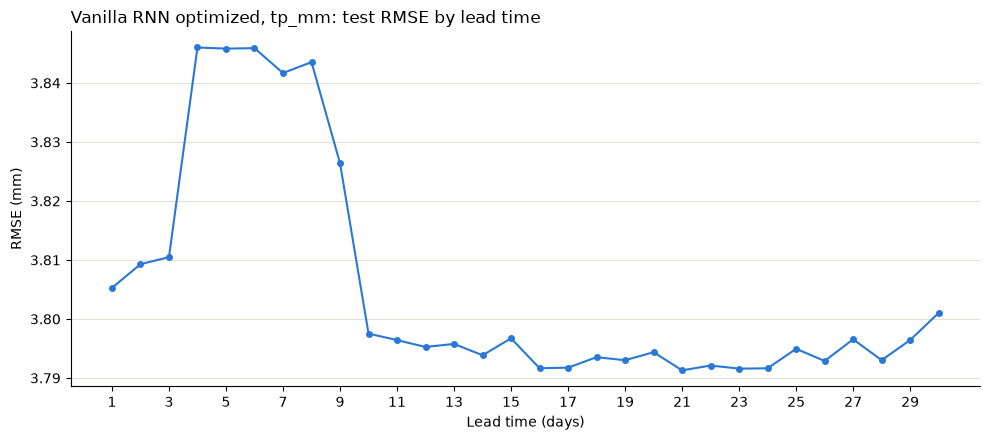

Test normalized MAE: 0.3725610377111257


In [12]:
best_params = study_rnn.best_params
print("Best hyperparameters:", best_params)

rnn, history, data, preds = run_config(cell="rnn", **best_params)

metrics.plot_training_history(history, metric="mse", title="Vanilla RNN optimized")
show_results("Vanilla RNN optimized", data, preds, splits=("train", "val", "test"))

y_test_pred = preds["test"]
print("Test normalized MAE:", normalized_mae(data["test"][1], y_test_pred))

models["Vanilla RNN"] = rnn 
test_predictions["Vanilla RNN"] = preds["test"]

## **GRU**

### DEFAULT PERFORMANCE

Epochs: 23


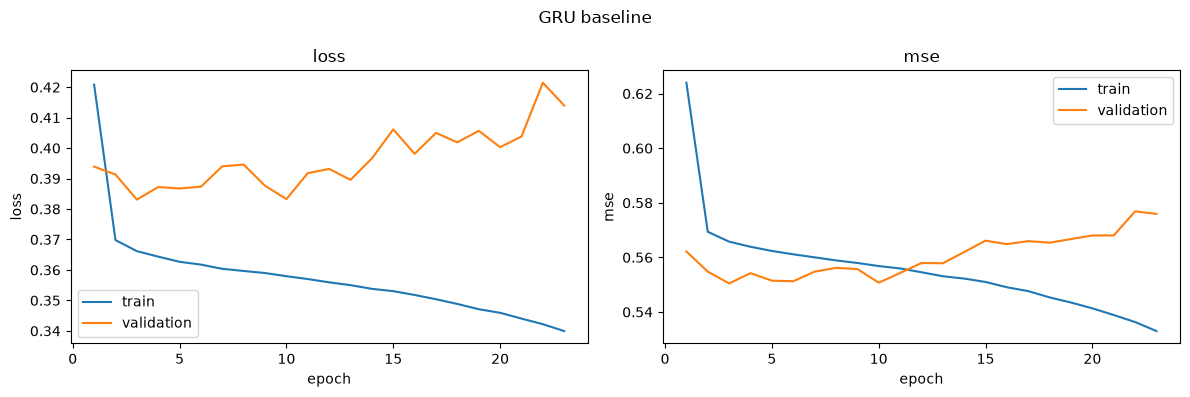

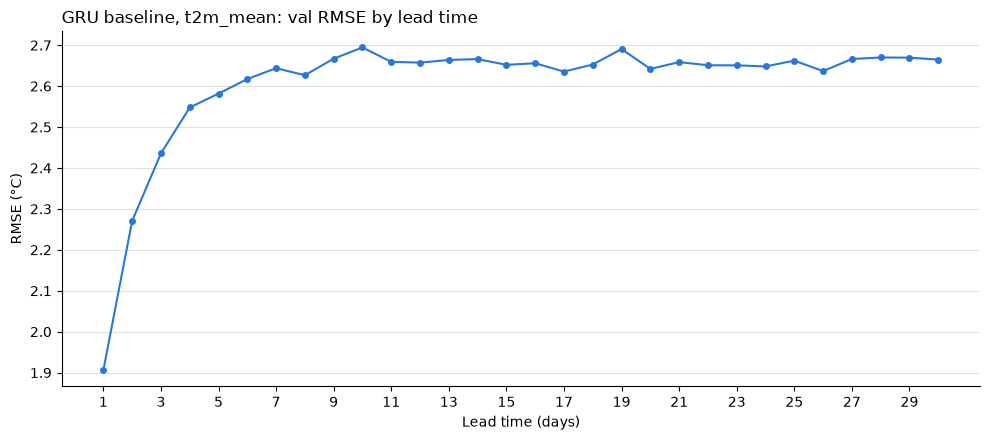

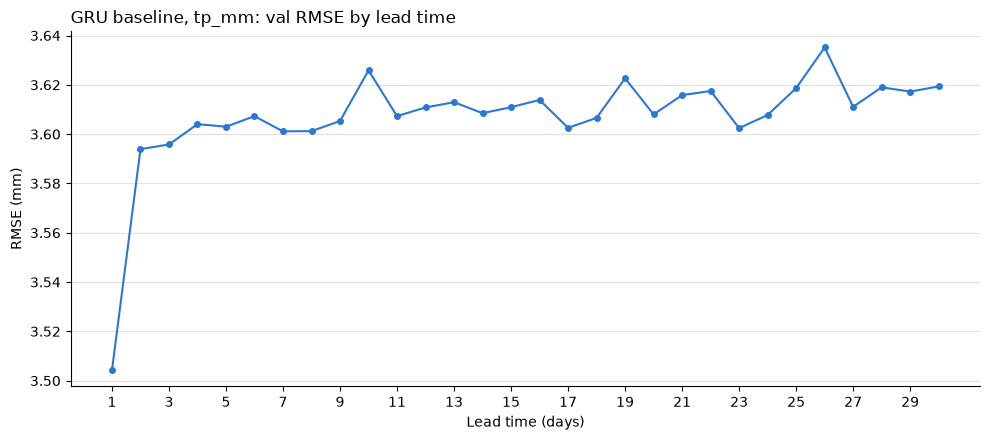

In [13]:
gru, history, data, preds = run_config(cell="gru")

print(f"Epochs: {len(history['loss'])}")
metrics.plot_training_history(history, metric="mse", title="GRU baseline")
show_results("GRU baseline", data, preds)

### MANUAL HYPERPARAMETER SEARCH

In [14]:
results_gru = manual_search("gru")
display(results_gru.round(4))

,seq_len,hidden_size,num_layers,epochs,Val normalized MAE,Val temp MAE,Val precip MAE
0,30,128,2,24,0.3795,2.0637,1.7803
1,14,32,2,23,0.3800,2.0990,1.7671
2,30,32,1,29,0.3801,2.0658,1.7836
3,14,128,1,23,0.3803,2.0880,1.7747
4,14,64,1,32,0.3804,2.1106,1.7647
5,14,32,1,37,0.3807,2.0906,1.7761
6,14,128,2,28,0.3807,2.1638,1.7415
7,30,32,2,23,0.3814,2.1064,1.7738
8,30,128,1,22,0.3815,2.0751,1.7896
9,14,64,2,22,0.3818,2.0991,1.7800


### OPTUNA

In [15]:
study_gru = run_study("gru", n_trials=50)

[I 2026-11-28 12:01:35,212] A new study created in memory with name: no-name-1feb44d3-ed07-4dae-84a0-b08a4b681054
Best trial: 0. Best value: 0.380074:   2%|▏         | 1/50 [00:04<03:30,  4.30s/it]

[I 2026-11-28 12:01:39,511] Trial 0 finished with value: 0.38007432121006013 and parameters: {'seq_len': 14, 'hidden_size': 24, 'num_layers': 1, 'dropout': 0.02904180608409973, 'lr': 0.005399484409787433, 'weight_decay': 6.358358856676247e-05, 'batch_size': 128}. Best is trial 0 with value: 0.38007432121006013.


Best trial: 0. Best value: 0.380074:   4%|▍         | 2/50 [00:09<03:43,  4.65s/it]

[I 2026-11-28 12:01:44,409] Trial 1 finished with value: 0.38299817654111945 and parameters: {'seq_len': 60, 'hidden_size': 68, 'num_layers': 2, 'dropout': 0.14561457009902096, 'lr': 0.0016738085788752138, 'weight_decay': 2.62108787826544e-06, 'batch_size': 256}. Best is trial 0 with value: 0.38007432121006013.


Best trial: 2. Best value: 0.378163:   6%|▌         | 3/50 [00:31<10:04, 12.86s/it]

[I 2026-11-28 12:02:07,029] Trial 2 finished with value: 0.3781632542816007 and parameters: {'seq_len': 30, 'hidden_size': 85, 'num_layers': 1, 'dropout': 0.03252579649263976, 'lr': 0.007902619549708232, 'weight_decay': 0.0007886714129990489, 'batch_size': 32}. Best is trial 2 with value: 0.3781632542816007.


... (91 outputs left out)

[I 2026-11-28 12:14:51,453] Trial 48 finished with value: 0.3747463787211977 and parameters: {'seq_len': 7, 'hidden_size': 42, 'num_layers': 3, 'dropout': 0.30704713926738647, 'lr': 0.00021717376041621215, 'weight_decay': 0.00011371726342518087, 'batch_size': 32}. Best is trial 29 with value: 0.37277185607442037.


Best trial: 29. Best value: 0.372772: 100%|██████████| 50/50 [13:22<00:00, 16.06s/it]

[I 2026-11-28 12:14:58,019] Trial 49 pruned. 
Best validation normalized MAE: 0.37277185607442037
Best hyperparameters: {'seq_len': 7, 'hidden_size': 24, 'num_layers': 3, 'dropout': 0.2488590374540949, 'lr': 0.0021592888995705817, 'weight_decay': 1.1084167526725327e-05, 'batch_size': 32}


,number,value,state
29,29,0.372772,COMPLETE
35,35,0.372818,COMPLETE
36,36,0.372973,COMPLETE
42,42,0.373100,COMPLETE
44,44,0.373306,COMPLETE
23,23,0.373383,COMPLETE
27,27,0.373492,COMPLETE
11,11,0.373527,COMPLETE
41,41,0.373625,COMPLETE
37,37,0.373673,COMPLETE


### TESTING

Best hyperparameters: {'seq_len': 7, 'hidden_size': 24, 'num_layers': 3, 'dropout': 0.2488590374540949, 'lr': 0.0021592888995705817, 'weight_decay': 1.1084167526725327e-05, 'batch_size': 32}


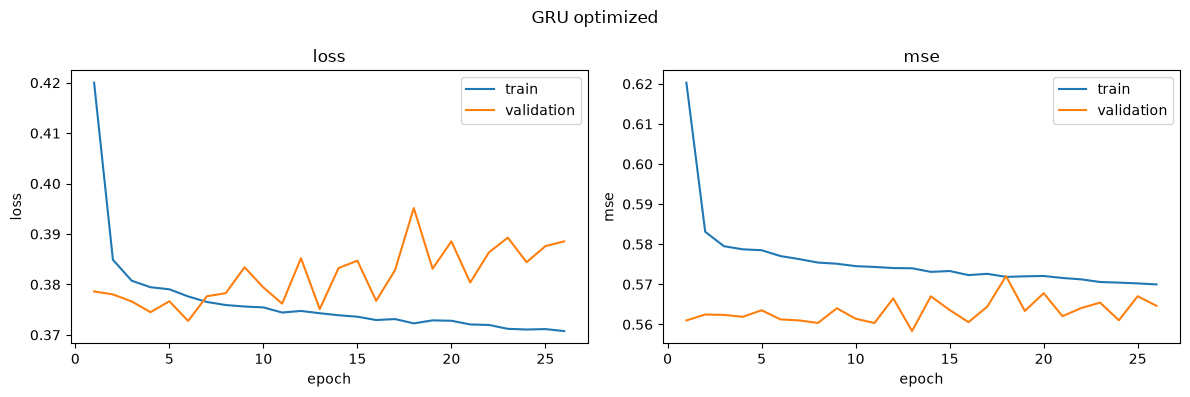

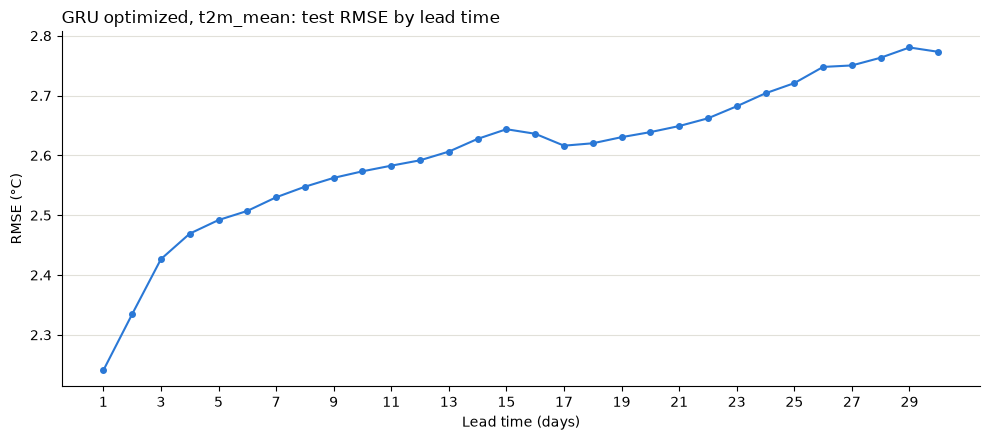

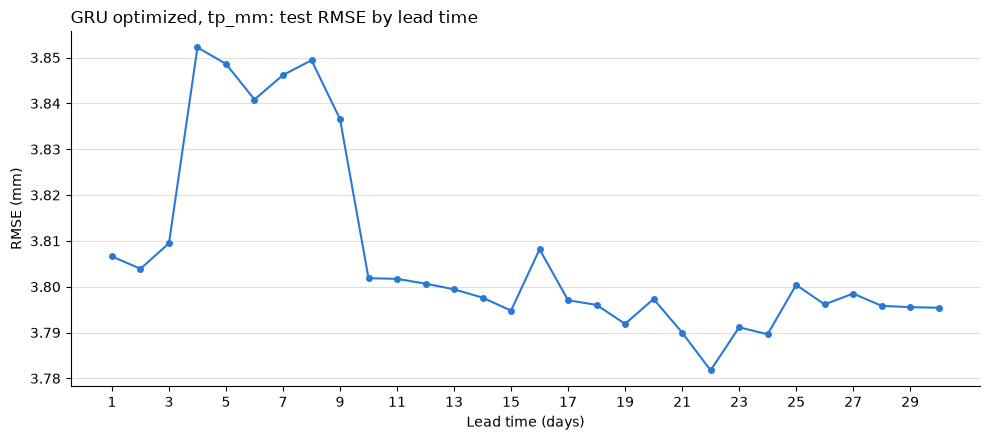

Test normalized MAE: 0.36927932989431034


In [16]:
best_params = study_gru.best_params
print("Best hyperparameters:", best_params)

gru, history, data, preds = run_config(cell="gru", **best_params)

metrics.plot_training_history(history, metric="mse", title="GRU optimized")
show_results("GRU optimized", data, preds, splits=("train", "val", "test"))

models["GRU"] = gru
test_predictions["GRU"] = preds["test"]
print("Test normalized MAE:", normalized_mae(data["test"][1], preds["test"]))

## **LSTM**

### DEFAULT PERFORMANCE

Epochs: 25


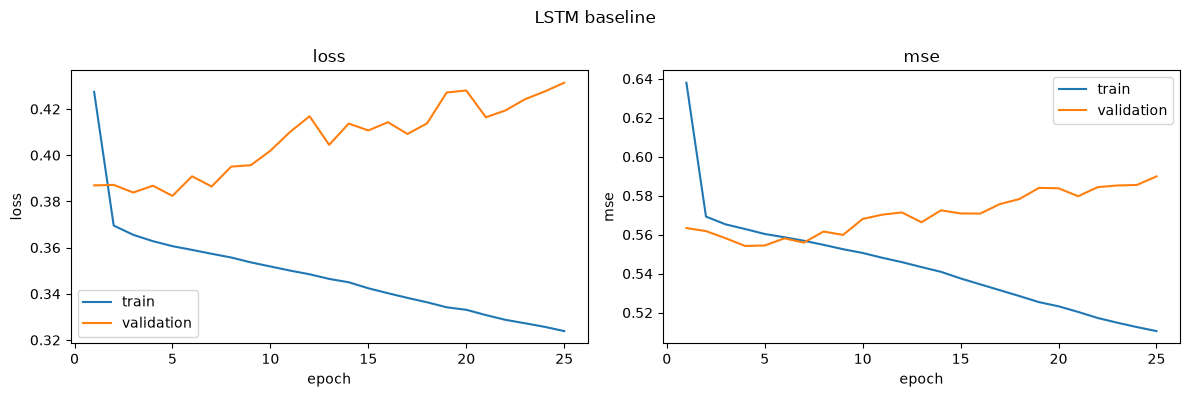

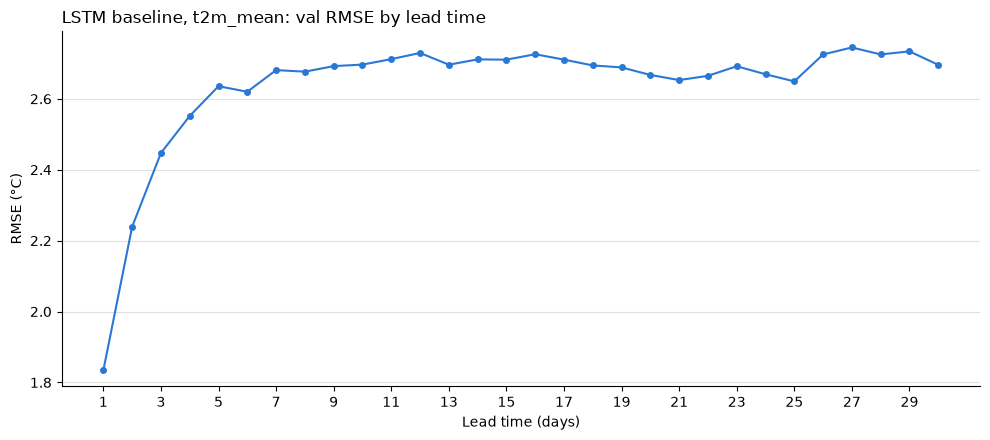

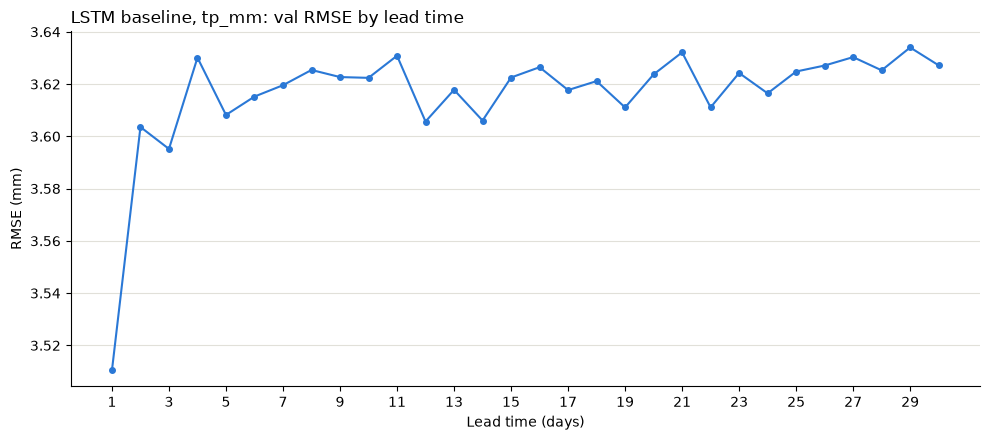

In [17]:
lstm, history, data, preds = run_config(cell="lstm")

print(f"Epochs: {len(history['loss'])}")
metrics.plot_training_history(history, metric="mse", title="LSTM baseline")
show_results("LSTM baseline", data, preds)

### MANUAL HYPERPARAMETER SEARCH

In [18]:
results_lstm = manual_search("lstm")
display(results_lstm.round(4))

,seq_len,hidden_size,num_layers,epochs,Val normalized MAE,Val temp MAE,Val precip MAE
0,14,32,2,23,0.3822,2.1708,1.7487
1,30,64,1,25,0.3824,2.0788,1.7941
2,60,128,1,22,0.3824,2.1014,1.7836
3,14,64,2,23,0.3826,2.1388,1.7671
4,60,64,1,26,0.3834,2.0987,1.7916
5,30,32,1,23,0.3836,2.1448,1.7714
6,14,64,1,26,0.3837,2.0895,1.7985
7,30,64,2,21,0.3838,2.2235,1.7354
8,14,128,1,21,0.3839,2.1538,1.7694
9,30,128,1,22,0.3843,2.1336,1.7817


### OPTUNA

In [19]:
study_lstm = run_study("lstm", n_trials=50)

[I 2026-11-28 12:17:17,907] A new study created in memory with name: no-name-7c2e0783-7157-4bf8-8441-f1103dc0db68
Best trial: 0. Best value: 0.381206:   2%|▏         | 1/50 [00:03<02:40,  3.29s/it]

[I 2026-11-28 12:17:21,192] Trial 0 finished with value: 0.3812060436208213 and parameters: {'seq_len': 14, 'hidden_size': 24, 'num_layers': 1, 'dropout': 0.02904180608409973, 'lr': 0.005399484409787433, 'weight_decay': 6.358358856676247e-05, 'batch_size': 128}. Best is trial 0 with value: 0.3812060436208213.


Best trial: 0. Best value: 0.381206:   4%|▍         | 2/50 [00:08<03:20,  4.17s/it]

[I 2026-11-28 12:17:25,984] Trial 1 finished with value: 0.3829871754192075 and parameters: {'seq_len': 60, 'hidden_size': 68, 'num_layers': 2, 'dropout': 0.14561457009902096, 'lr': 0.0016738085788752138, 'weight_decay': 2.62108787826544e-06, 'batch_size': 256}. Best is trial 0 with value: 0.3812060436208213.


Best trial: 2. Best value: 0.376954:   6%|▌         | 3/50 [00:30<09:40, 12.36s/it]

[I 2026-11-28 12:17:48,080] Trial 2 finished with value: 0.37695399147258735 and parameters: {'seq_len': 30, 'hidden_size': 85, 'num_layers': 1, 'dropout': 0.03252579649263976, 'lr': 0.007902619549708232, 'weight_decay': 0.0007886714129990489, 'batch_size': 32}. Best is trial 2 with value: 0.37695399147258735.


... (91 outputs left out)

[I 2026-11-28 12:25:22,480] Trial 48 finished with value: 0.37291618417274186 and parameters: {'seq_len': 7, 'hidden_size': 185, 'num_layers': 3, 'dropout': 0.1752694417316341, 'lr': 0.0007003712508712032, 'weight_decay': 0.000203833717285478, 'batch_size': 128}. Best is trial 48 with value: 0.37291618417274186.


Best trial: 48. Best value: 0.372916: 100%|██████████| 50/50 [08:10<00:00,  9.81s/it]

[I 2026-11-28 12:25:28,336] Trial 49 finished with value: 0.3739635835533593 and parameters: {'seq_len': 7, 'hidden_size': 124, 'num_layers': 3, 'dropout': 0.15193331359051004, 'lr': 0.0007114659134366769, 'weight_decay': 0.00025851881076596777, 'batch_size': 128}. Best is trial 48 with value: 0.37291618417274186.
Best validation normalized MAE: 0.37291618417274186
Best hyperparameters: {'seq_len': 7, 'hidden_size': 185, 'num_layers': 3, 'dropout': 0.1752694417316341, 'lr': 0.0007003712508712032, 'weight_decay': 0.000203833717285478, 'batch_size': 128}


,number,value,state
48,48,0.372916,COMPLETE
40,40,0.373207,COMPLETE
46,46,0.373267,COMPLETE
23,23,0.373667,COMPLETE
39,39,0.373716,COMPLETE
45,45,0.373775,COMPLETE
49,49,0.373964,COMPLETE
19,19,0.374133,COMPLETE
16,16,0.374661,COMPLETE
43,43,0.374717,COMPLETE


### TESTING

Best hyperparameters: {'seq_len': 7, 'hidden_size': 185, 'num_layers': 3, 'dropout': 0.1752694417316341, 'lr': 0.0007003712508712032, 'weight_decay': 0.000203833717285478, 'batch_size': 128}


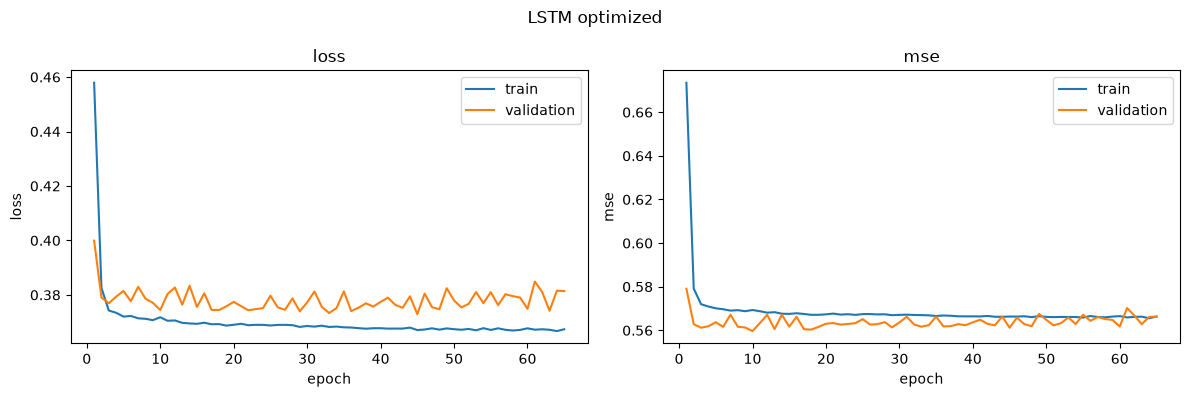

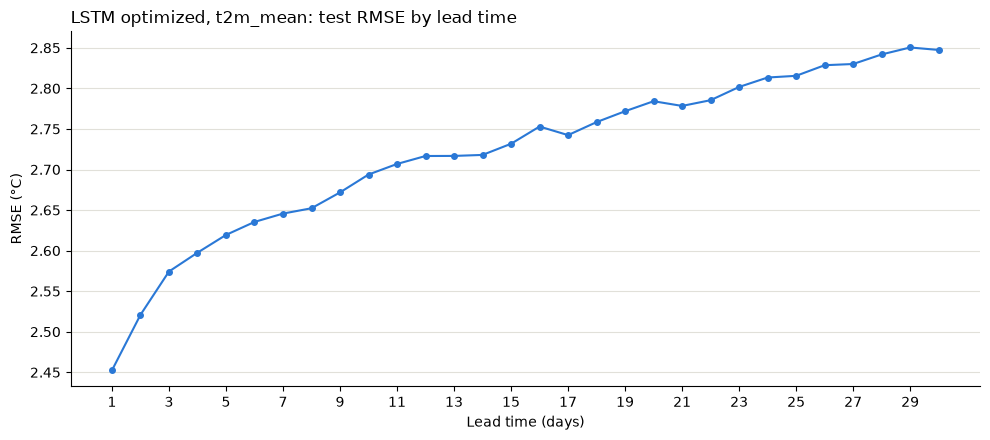

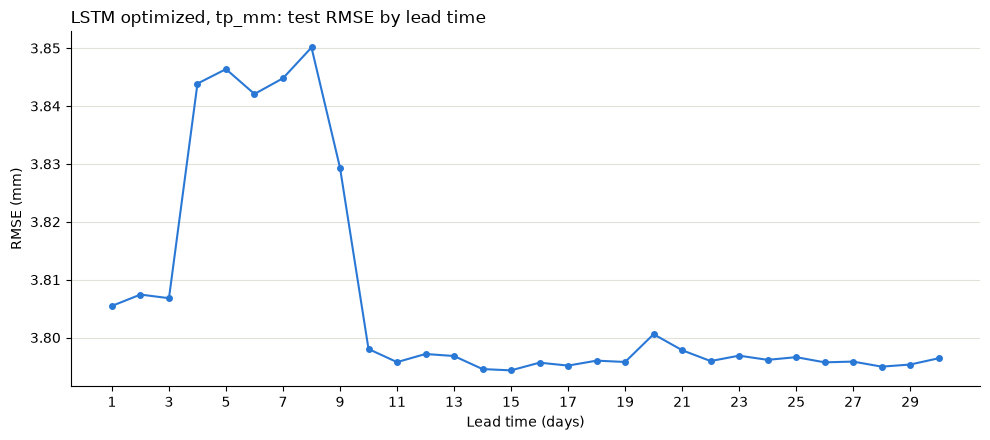

Test normalized MAE: 0.37479905370412925


In [20]:
best_params = study_lstm.best_params
print("Best hyperparameters:", best_params)

lstm, history, data, preds = run_config(cell="lstm", **best_params)

metrics.plot_training_history(history, metric="mse", title="LSTM optimized")
show_results("LSTM optimized", data, preds, splits=("train", "val", "test"))

models["LSTM"] = lstm
test_predictions["LSTM"] = preds["test"]
print("Test normalized MAE:", normalized_mae(data["test"][1], preds["test"]))

## COMPARISON

In [21]:
y_true = data["test"][1]  # le righe di test sono identiche per ogni seq_len

comparison = pd.DataFrame([
    {
        "Model": name,
        "Temperature": normalized_mae(y_true[["t2m_mean"]], y_pred[["t2m_mean"]]),
        "Precipitation": normalized_mae(y_true[["tp_mm"]], y_pred[["tp_mm"]]),
        "Overall": normalized_mae(y_true, y_pred),
    }
    for name, y_pred in test_predictions.items()
]).sort_values("Overall").reset_index(drop=True)

comparison.index += 1
comparison.index.name = "Rank"
display(comparison.style.format({c: "{:.5f}" for c in ["Temperature", "Precipitation", "Overall"]}))

,Model,Temperature,Precipitation,Overall
Rank,,,,
1,GRU,0.26856,0.47000,0.36928
2,Vanilla RNN,0.27382,0.47131,0.37256
3,LSTM,0.27937,0.47023,0.37480
